In [1]:
# SETUP: imports, plot style and shared helpers
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401  (registers the "science" and "ieee" styles)
from matplotlib.ticker import MultipleLocator

# ---- Plot style -------------------------------------------------------------
plt.style.use(["science", "ieee"])

tick_font = 10.4
axis_label_font = 11.0
legend_font = 10.0

mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": tick_font,
    "axes.labelsize": axis_label_font,
    "xtick.labelsize": tick_font,
    "ytick.labelsize": tick_font,
    "legend.fontsize": legend_font,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# Temperatures are colored along a sequential colormap (cool = low T, hot = high T)
temperature_cmap = plt.cm.plasma

# ---- Shared model helpers ---------------------------------------------------
R_KJ = 8.314462618e-3  # gas constant [kJ/(mol K)]


def to_kelvin(T_C):
    return T_C + 273.15


def arrhenius(A, E, T_K):
    """k = A * exp(-E / (R T)), with E in kJ/mol."""
    return A * np.exp(-E / (R_KJ * T_K))


def power_law_activity(base, exponent):
    """Activity a = base**exponent, set to 0 once the catalyst is fully
    deactivated (base <= 0), and clipped to [0, 1]."""
    activity = np.zeros_like(base, dtype=float)
    active = base > 0.0
    activity[active] = base[active] ** exponent
    return np.clip(activity, 0.0, 1.0)


def scalar_if_0d(activity):
    """Return a float for a scalar time input, otherwise the array."""
    return activity.item() if activity.ndim == 0 else activity

In [2]:
# NICKEL MODEL
#   a(t) = (1 - B t)^0.8,  with  B = 0.5 * kd * (kd_c + kd_ch4 * P_CH4 + kd_h2 * P_H2^0.83)
#   Every rate constant is Arrhenius: (A, E [kJ/mol]). Pressures in Pa.
deactivation_constants_Ni = {
    "kd":     np.array([18.39, 147.0]),
    "kd_c":   np.array([309.87, -26.0]),
    "kd_ch4": np.array([-0.004431483, -5.376]),
    "kd_h2":  np.array([-2.44388e-05, -80.19]),
}


def deactivation_nickel(T_C, Pch4, Ph2, t_s, da_constants):
    """Activity of the Ni catalyst after t_s seconds at T_C [°C]."""
    T_K = to_kelvin(T_C)
    k = {name: arrhenius(A, E, T_K) for name, (A, E) in da_constants.items()}

    deactivation_term = k["kd_c"] + k["kd_ch4"] * Pch4 + k["kd_h2"] * Ph2**0.83
    B = 0.5 * k["kd"] * deactivation_term

    t_s = np.asarray(t_s, dtype=float)
    activity = power_law_activity(1.0 - B * t_s, 0.8)
    return scalar_if_0d(activity)


temperatures_Ni = np.arange(550, 701, 50)  # 550-700 °C

# Operating pressures [Pa]
Pch4_Ni = 0.5e5
Ph2_Ni = 0.0e5

In [3]:
# IRON MODEL
#   a(t) = a_inf / (1 - (1 - a_inf) * exp(-a_inf * kd * M_C * r0 * t))
#   r0 is the initial CH4 decomposition rate; constants are (k_ref, E [kJ/mol], T_ref [K]).
#   Pressures in Pa.
reaction_constants_Fe = {
    "k": np.array([1.283e-08, 160.0, 1073.0])
}

deactivation_constants_Fe = {
    "kd": np.array([2.0, 77.0, 1073.0])
}

# The iron model uses the CODATA 2014 gas constant
R_KJ_FE = 8.3144598e-3  # [kJ/(mol K)]
R_J_FE = 8.3144598      # [J/(mol K)]

P0 = 1e5          # standard pressure, 1 bar [Pa]
M_C = 12.011      # molar mass of carbon [g/mol]
a_inf_Fe = 0.001  # residual activity at t -> infinity


def arrhenius_ref(k_ref, E, T_ref, T_K):
    """k = k_ref * exp(-(E / R) * (1/T - 1/T_ref)), with E in kJ/mol."""
    return k_ref * np.exp(-(E / R_KJ_FE) * (1.0 / T_K - 1.0 / T_ref))


def equilibrium_constant_iron(T_K):
    """Equilibrium constant of CH4 <-> C + 2 H2."""
    delta_G0 = 89658.88 - 102.27 * T_K - 0.00428 * T_K**2 - 2499358.99 / T_K  # [J/mol]
    return np.exp(-delta_G0 / (R_J_FE * T_K))


def initial_reaction_rate_iron(T_C, Pch4, Ph2, r_constants):
    T_K = to_kelvin(T_C)
    k = arrhenius_ref(*r_constants["k"], T_K)
    Keq = equilibrium_constant_iron(T_K)

    driving_force = Pch4 - Ph2**2 / (Keq * P0)
    return k * driving_force


def deactivation_iron(T_C, Pch4, Ph2, t_s, r_constants, da_constants):
    """Activity of the Fe catalyst after t_s seconds at T_C [°C]."""
    kd = arrhenius_ref(*da_constants["kd"], to_kelvin(T_C))
    r0 = initial_reaction_rate_iron(T_C, Pch4, Ph2, r_constants)

    t_s = np.asarray(t_s, dtype=float)
    coefficient = kd * M_C * r0
    decay = np.exp(-a_inf_Fe * coefficient * t_s)
    activity = a_inf_Fe / (1.0 - (1.0 - a_inf_Fe) * decay)

    activity = np.clip(activity, a_inf_Fe, 1.0)
    return scalar_if_0d(activity)


temperatures_Fe = np.arange(700, 851, 50)  # 700-850 °C

# Operating pressures [Pa]
Pch4_Fe = 0.5e5
Ph2_Fe = 0.0e5

In [4]:
# ACTIVATED CARBON MODEL
#   a(t) = (1 - K t)^(1 / (1 - d)),  with  K = (1 - d) * kd * P_CH4^m
#   and  m = 112 * (T / T_c,CH4)^-2.9551.  kd is Arrhenius: (A, E [kJ/mol]).
#   Pressure in atm.
deactivation_constants_AC = {
    "kd": np.array([943786.6667, 194.0])
}

d_AC = 0.5          # deactivation order parameter
T_CRIT_CH4 = 190.4  # critical temperature of CH4 [K]


def deactivation_carbon(T_C, Pch4_atm, t_s, da_constants):
    """Activity of the activated-carbon catalyst after t_s seconds at T_C [°C]."""
    T_K = to_kelvin(T_C)
    kd = arrhenius(*da_constants["kd"], T_K)

    m = 112.0 * (T_K / T_CRIT_CH4) ** (-2.9551)
    K = (1.0 - d_AC) * kd * Pch4_atm**m

    t_s = np.asarray(t_s, dtype=float)
    activity = power_law_activity(1.0 - K * t_s, 1.0 / (1.0 - d_AC))
    return scalar_if_0d(activity)


temperatures_AC = np.arange(800, 951, 50)  # 800-950 °C

# Operating pressure [atm] (0.5 bar)
Pch4_AC_atm = 0.5 / 1.01325

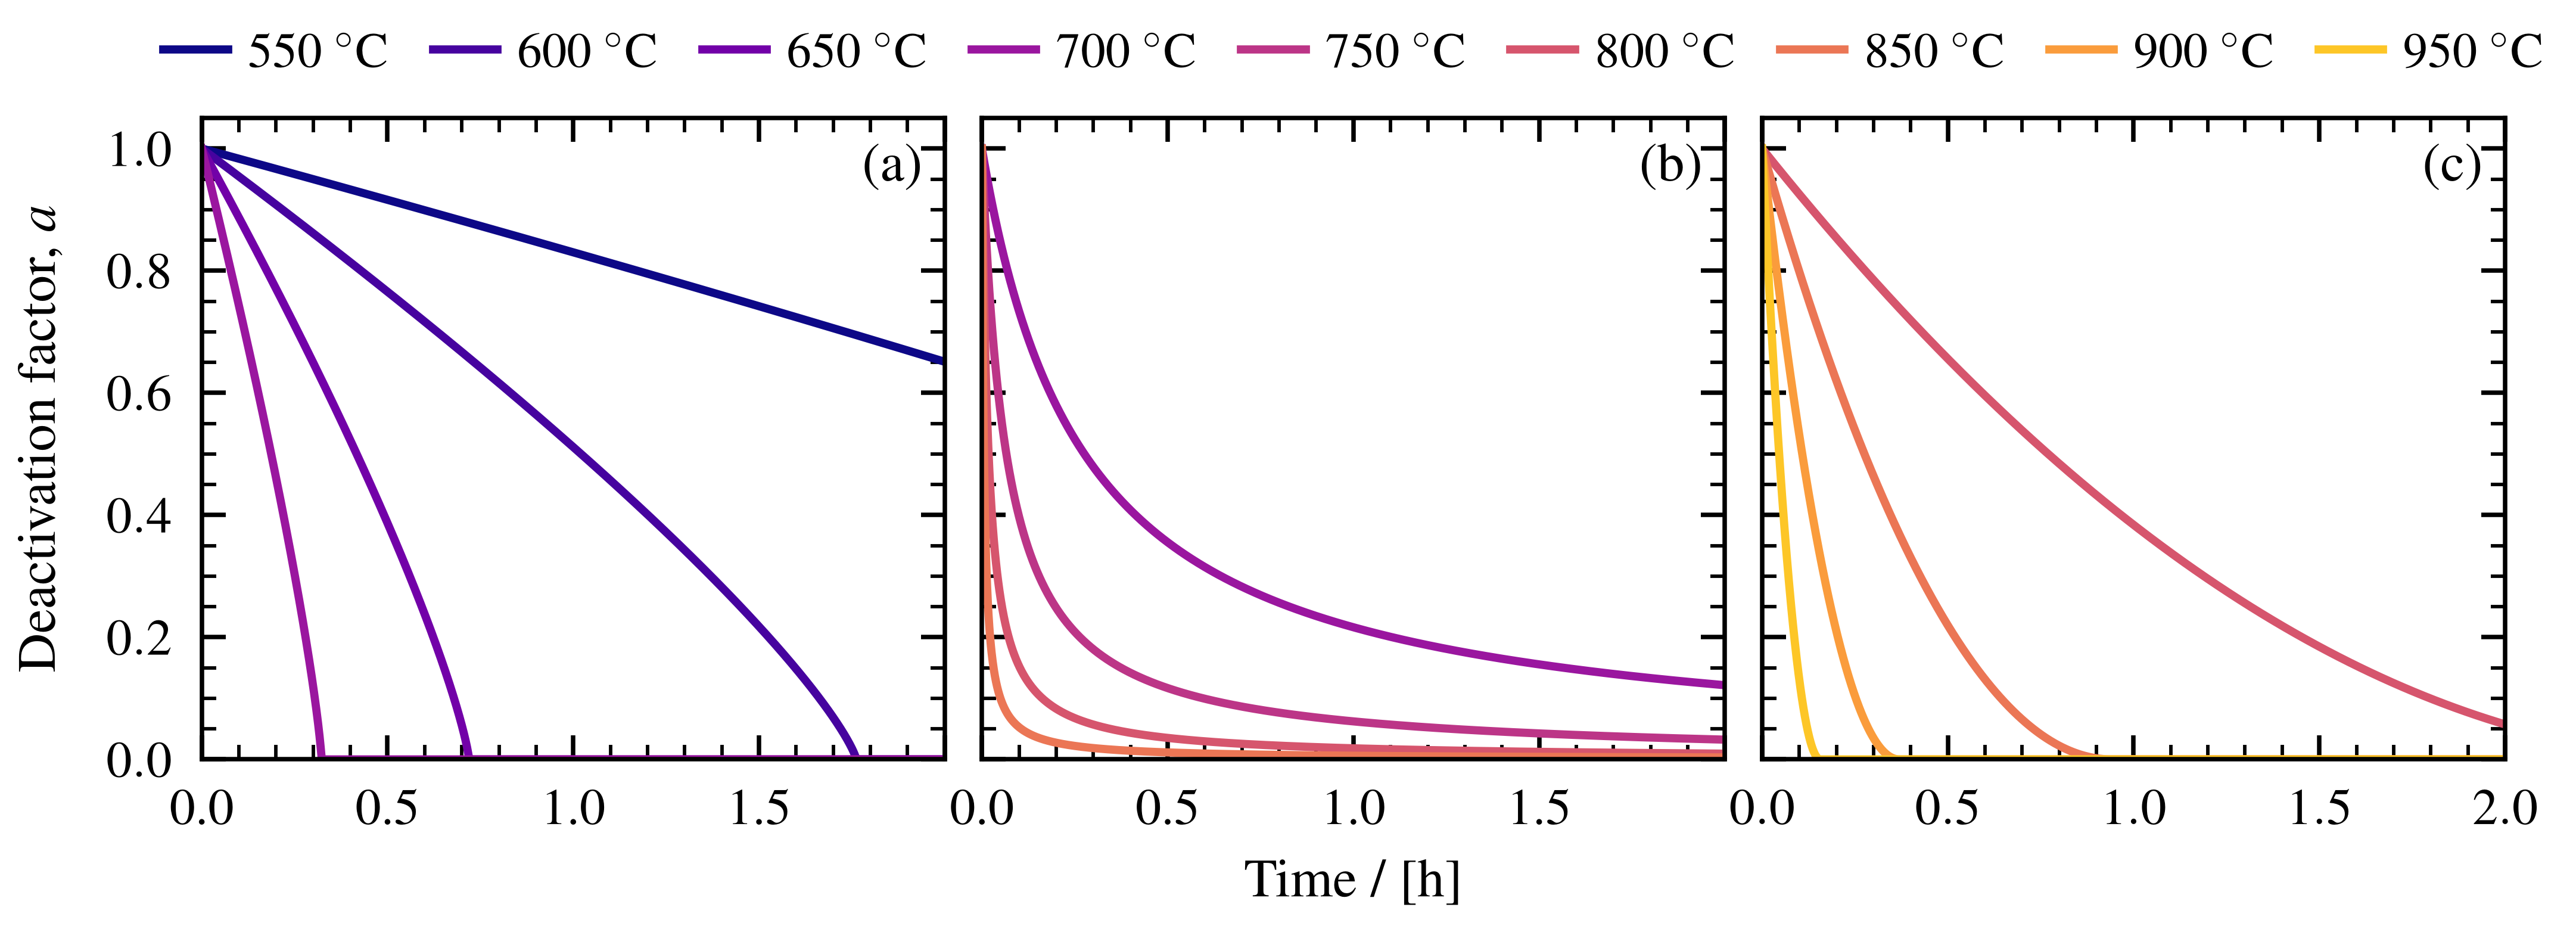

In [5]:
# PLOT: activity vs. time for all catalysts in one figure (shared y-axis)
from matplotlib.lines import Line2D

# Common time range
time_h = np.linspace(0.0, 2.0, 2000)
time_s = time_h * 3600.0

fig_size = (7.16, 2.6)  # IEEE double-column width [in]
panel_font = 11.0

# (temperatures, activity as a function of T_C) for each panel
catalysts = [
    (temperatures_Ni,
     lambda T_C: deactivation_nickel(T_C, Pch4_Ni, Ph2_Ni, time_s, deactivation_constants_Ni)),
    (temperatures_Fe,
     lambda T_C: deactivation_iron(T_C, Pch4_Fe, Ph2_Fe, time_s,
                                   reaction_constants_Fe, deactivation_constants_Fe)),
    (temperatures_AC,
     lambda T_C: deactivation_carbon(T_C, Pch4_AC_atm, time_s, deactivation_constants_AC)),
]

# One color per temperature, shared by all panels (cool = low T, hot = high T)
all_temperatures = np.unique(np.concatenate([temps for temps, _ in catalysts]))
temperature_color = {
    T_C: temperature_cmap(x)
    for T_C, x in zip(all_temperatures, np.linspace(0.0, 0.88, len(all_temperatures)))
}


def temperature_label(T_C):
    return fr"{T_C:.0f} $^\circ\mathrm{{C}}$"


def style_axis(ax, show_last_xlabel=True):
    ax.set_xlim(0.0, 2.0)
    ax.set_ylim(0.0, 1.05)

    ax.xaxis.set_major_locator(MultipleLocator(0.5))
    ax.xaxis.set_minor_locator(MultipleLocator(0.1))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))

    # Panels sit close together: drop the "2.0" label so it does not
    # collide with the "0.0" label of the next panel
    if not show_last_xlabel:
        ax.set_xticks(np.arange(0.0, 2.01, 0.5), ["0.0", "0.5", "1.0", "1.5", ""])

    # Inward ticks on all four sides
    ax.tick_params(axis="both", which="both", direction="in", colors="black",
                   top=True, bottom=True, left=True, right=True)
    ax.tick_params(axis="both", which="major", length=4.8, width=0.9, pad=6,
                   labelsize=tick_font)
    ax.tick_params(axis="both", which="minor", length=2.9, width=0.7)

    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(0.9)


def add_temperature_legend(fig):
    handles = [Line2D([], [], color=temperature_color[T_C], linewidth=1.65,
                      label=temperature_label(T_C))
               for T_C in all_temperatures]
    fig.legend(
        handles=handles,
        ncol=len(handles),
        loc="upper center",
        bbox_to_anchor=(0.5 * (fig_margins["left"] + fig_margins["right"]), 0.995),
        frameon=False,
        columnspacing=0.9,
        handlelength=1.3,
        handletextpad=0.4,
        borderpad=0.3,
        fontsize=legend_font,
    )


fig_margins = dict(left=0.085, right=0.985, bottom=0.17, top=0.86, wspace=0.05)

fig, axes = plt.subplots(1, len(catalysts), figsize=fig_size, sharey=True)

for i, (ax, (temperatures_C, activity_at)) in enumerate(zip(axes, catalysts)):
    for T_C in temperatures_C:
        ax.plot(time_h, activity_at(T_C), color=temperature_color[T_C],
                linestyle="-", linewidth=1.65)

    style_axis(ax, show_last_xlabel=(i == len(axes) - 1))

    # Panel letter in the top-right corner, inside the axes
    ax.text(0.97, 0.96, f"({'abc'[i]})", transform=ax.transAxes,
            ha="right", va="top", fontsize=panel_font)

axes[0].set_ylabel(r"Deactivation factor, $a$", fontsize=axis_label_font, labelpad=8)
# Centered on the span of the three panels, not on the whole figure
panels_center = 0.5 * (fig_margins["left"] + fig_margins["right"])
fig.supxlabel(r"Time / [h]", x=panels_center, y=0.01, fontsize=axis_label_font)

fig.subplots_adjust(**fig_margins)
add_temperature_legend(fig)
# PDF is vector; dpi sets the resolution of any rasterized 
# content (min. 500 ppi)
fig.savefig("figure-7.pdf", format="pdf", dpi=500)

plt.show()

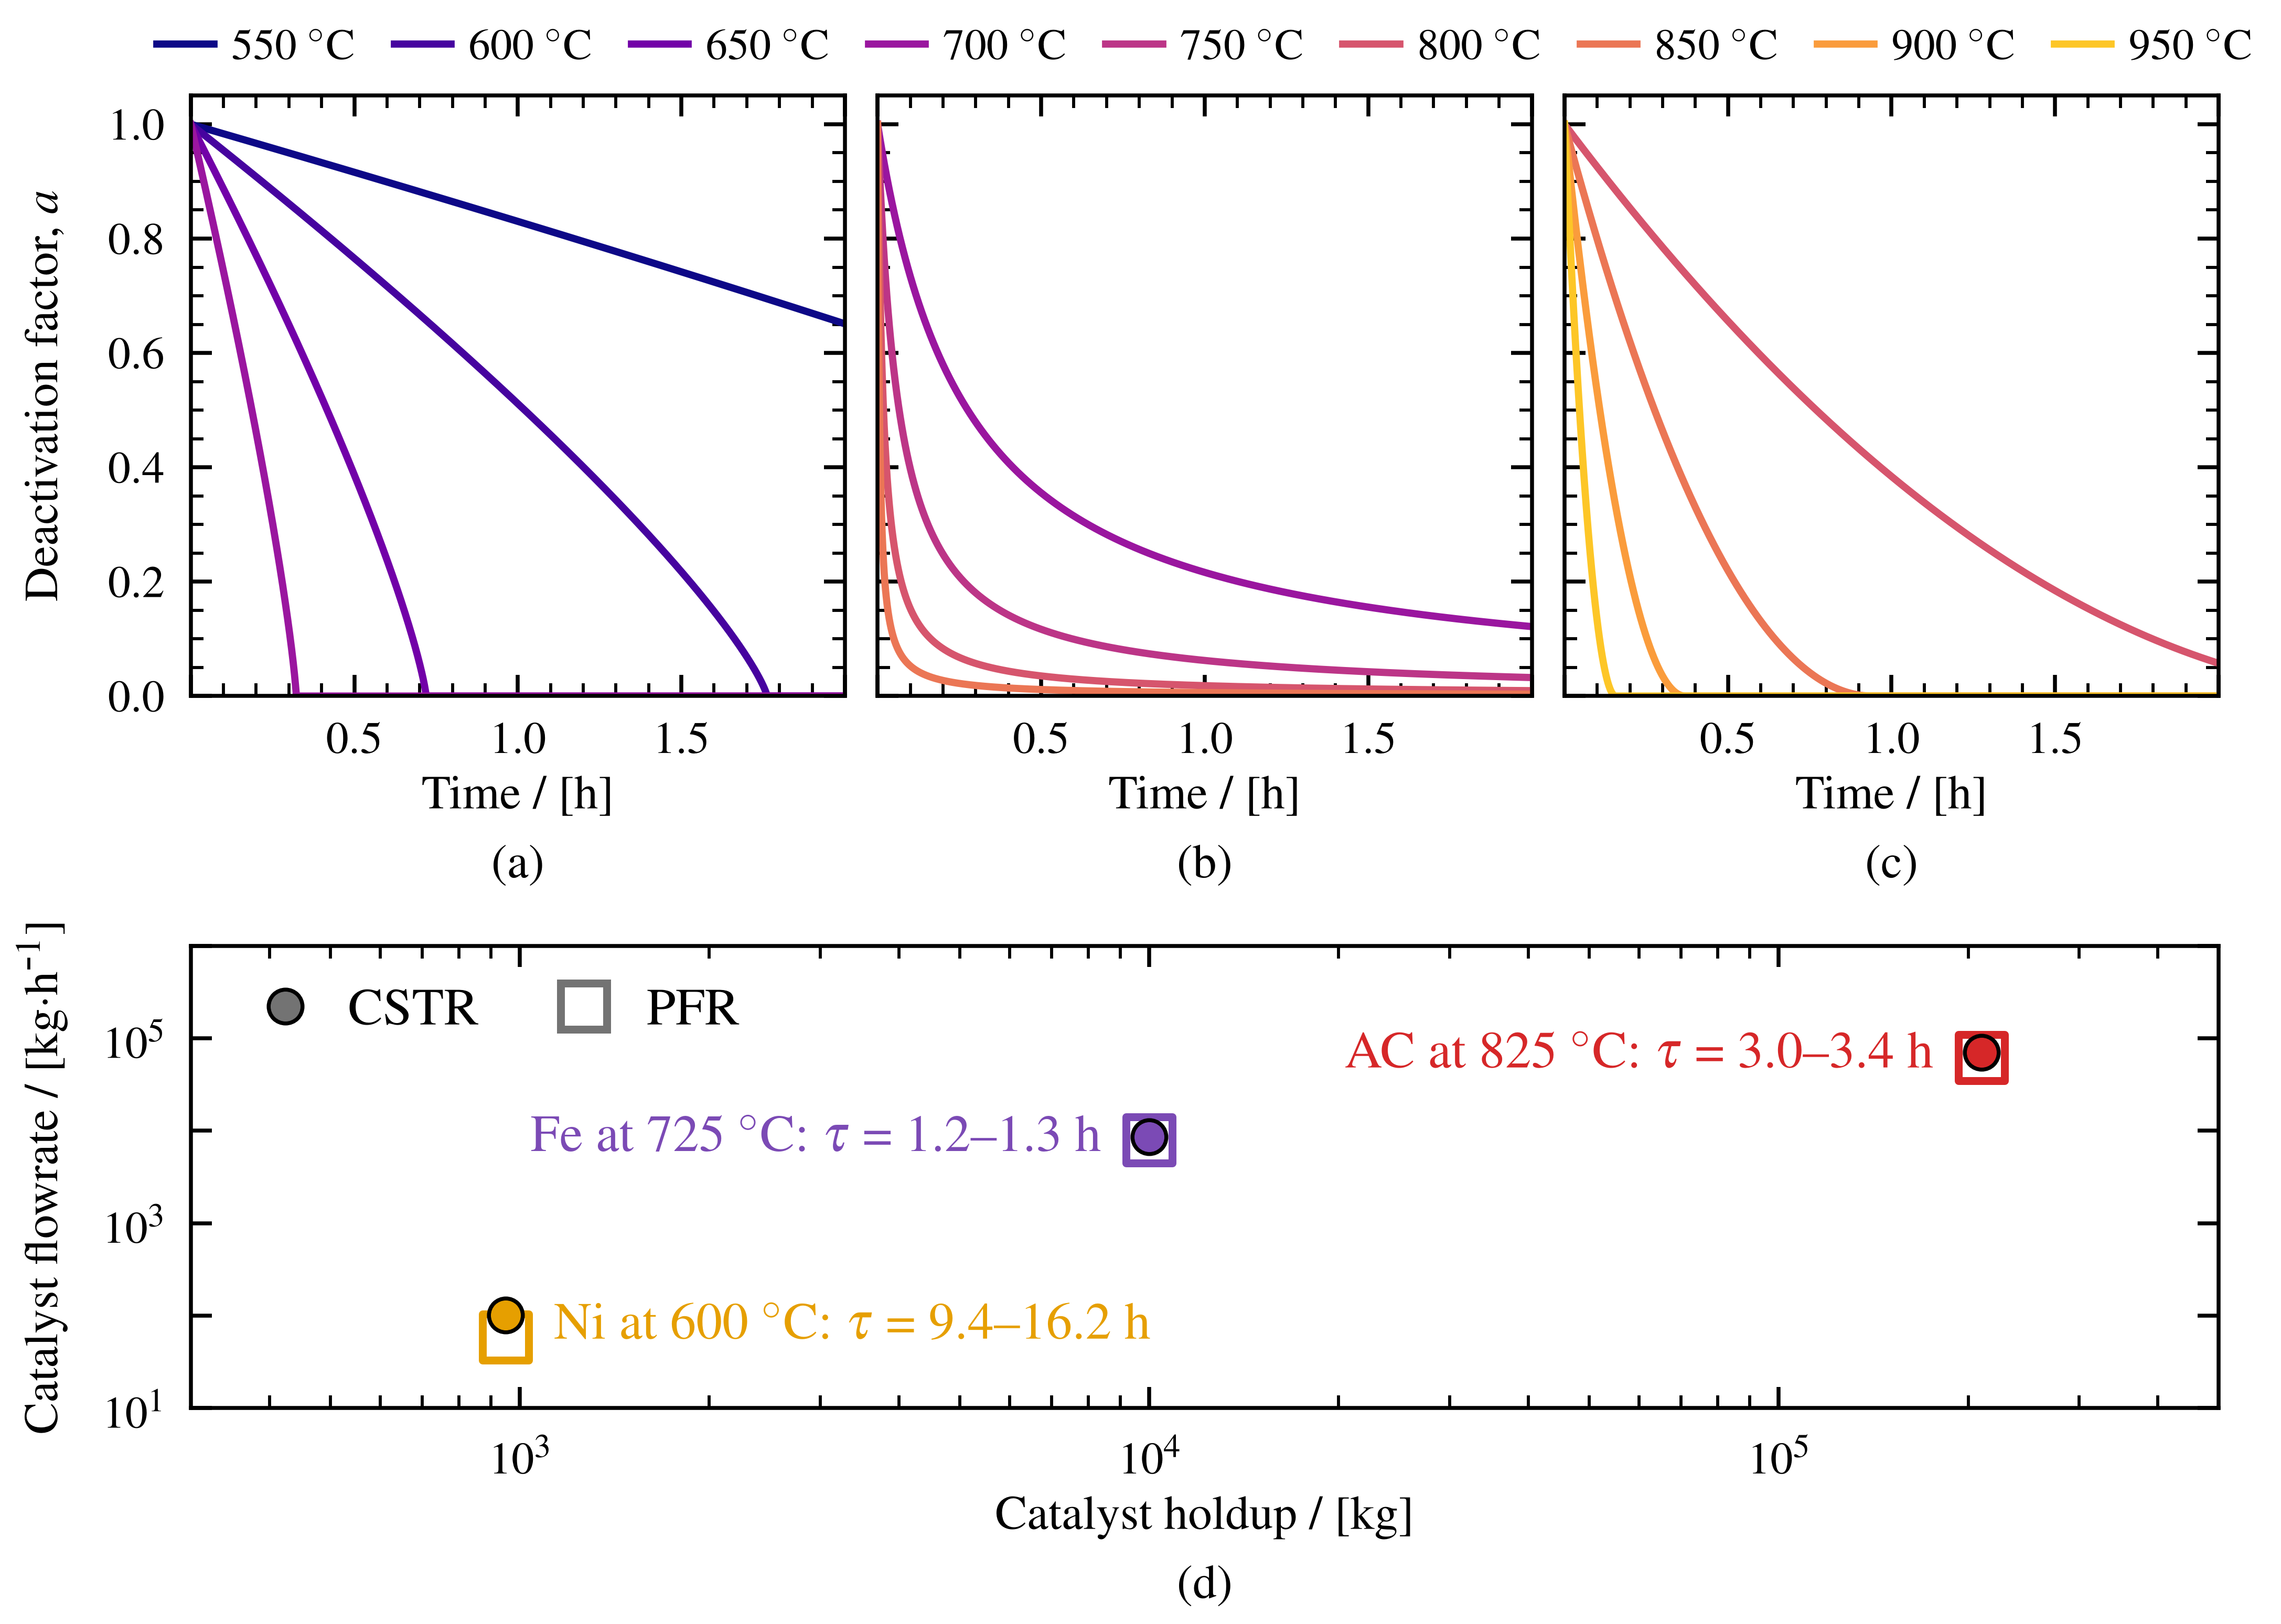

In [6]:
# PLOT: (a)-(c) activity vs. time, plus (d) catalyst inventory vs. flow rate underneath
#   Panel (d) reads the catalyst flow rates from the simulation results
#   (same data as catalyst_amount_and_rate.ipynb).
from pathlib import Path

import pandas as pd
from matplotlib.ticker import FuncFormatter

# ---- Data for panel (d) -------------------------------------------------------
# Selected case per catalyst: operating temperature [C], inventory [kg], results folder
selected_cases = {
    "Ni": (600, 950, "NiMP"),
    "Fe": (725, 10_000, "FeMP"),
    "AC": (825, 210_000, "ACMP"),
}
reactors = ["CSTR", "PFR"]
catalyst_colors = {"Ni": "#E69F00", "Fe": "#7B4AB5", "AC": "#D62728"}


def catalyst_flow_rate(folder, reactor, T_C, inventory):
    """Catalyst flow rate [kg/h] from the simulation result of one case."""
    file = (Path("..") / folder / "Results_Simulations" /
            f"sim-{reactor}-100TPD-ch4-t{T_C}-p1.07-c{inventory}-da0.2-psa15.csv")
    return pd.read_csv(file)["Cat Rate [kg/h]"].iloc[0]


flow_rates = {
    name: {r: catalyst_flow_rate(folder, r, T_C, inv) for r in reactors}
    for name, (T_C, inv, folder) in selected_cases.items()
}

# ---- Figure layout ------------------------------------------------------------
fig_margins_4 = dict(left=0.085, right=0.985, bottom=0.125, top=0.935)

fig = plt.figure(figsize=(7.16, 5.15))  # IEEE double-column width [in]
grid = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.77], hspace=0.47, wspace=0.05,
                        **fig_margins_4)
axes_top = [fig.add_subplot(grid[0, 0])]
axes_top += [fig.add_subplot(grid[0, i], sharey=axes_top[0]) for i in (1, 2)]
ax_d = fig.add_subplot(grid[1, :])

# ---- (a)-(c): activity vs. time -------------------------------------------------
for i, (ax, (temperatures_C, activity_at)) in enumerate(zip(axes_top, catalysts)):
    for T_C in temperatures_C:
        ax.plot(time_h, activity_at(T_C), color=temperature_color[T_C],
                linestyle="-", linewidth=1.65)
    style_axis(ax)
    # hide the "0.0" and "2.0" labels on x (ticks stay)
    ax.set_xticks(np.arange(0.0, 2.01, 0.5), ["", "0.5", "1.0", "1.5", ""])
    ax.set_yticks(np.arange(0.0, 1.01, 0.2), ["0.0", "0.2", "0.4", "0.6", "0.8", "1.0"])
    if i > 0:
        ax.tick_params(labelleft=False)
    ax.set_xlabel(r"Time / [h]", fontsize=axis_label_font, labelpad=3)

axes_top[0].set_ylabel(r"Deactivation factor, $a$", fontsize=axis_label_font, labelpad=8)

fig.legend(
    handles=[Line2D([], [], color=temperature_color[T_C], linewidth=1.65,
                    label=temperature_label(T_C)) for T_C in all_temperatures],
    ncol=len(all_temperatures), loc="upper center",
    bbox_to_anchor=(0.5 * (fig_margins_4["left"] + fig_margins_4["right"]), 0.998),
    frameon=False, columnspacing=0.9, handlelength=1.3, handletextpad=0.4,
    borderpad=0.3, fontsize=legend_font,
)

# ---- (d): catalyst inventory vs. flow rate ------------------------------------------
d_font = 12.0                      # text inside panel (d): catalyst labels and legend
pfr_size, cstr_size = 110, 60      # marker areas [pt^2]
labels_left = {"Fe", "AC"}         # catalysts whose label sits left of the marker

for name, (T_C, inventory, _) in selected_cases.items():
    rate = flow_rates[name]
    color = catalyst_colors[name]
    # PFR: open square; CSTR: smaller filled circle drawn on top
    ax_d.scatter(inventory, rate["PFR"], s=pfr_size, marker="s", facecolor="white",
                 edgecolor=color, linewidth=1.8, zorder=3)
    ax_d.scatter(inventory, rate["CSTR"], s=cstr_size, marker="o", facecolor=color,
                 edgecolor="black", linewidth=0.9, zorder=4)

    tau_cstr, tau_pfr = inventory / rate["CSTR"], inventory / rate["PFR"]
    ax_d.annotate(
        rf"{name} at {T_C} $^\circ$C:  $\tau$ = {tau_cstr:.1f}--{tau_pfr:.1f} h",
        xy=(inventory, np.sqrt(rate["CSTR"] * rate["PFR"])), xytext=(-11 if name in labels_left else 11, 0),
        textcoords="offset points", ha="right" if name in labels_left else "left", va="center",
        fontsize=d_font, color=color,
    )

ax_d.set_xscale("log")
ax_d.set_yscale("log")
ax_d.set_xlim(3e2, 5e5)
ax_d.set_ylim(1e1, 1e6)

def power_of_ten(value, position=None):
    """Tick label in scientific notation, e.g. 10^3."""
    return rf"$10^{{{round(np.log10(value))}}}$"


ax_d.xaxis.set_major_formatter(FuncFormatter(power_of_ten))
ax_d.yaxis.set_major_locator(mpl.ticker.LogLocator(base=10, subs=[1.0], numticks=10))
ax_d.yaxis.set_minor_formatter(FuncFormatter(lambda value, position: ""))
# tick every decade on y, but label only every other one so the short axis stays uncluttered
ax_d.yaxis.set_major_formatter(FuncFormatter(
    lambda value, position: power_of_ten(value) if round(np.log10(value)) % 2 == 1 else ""))

ax_d.tick_params(axis="both", which="both", direction="in", top=True, right=True)
ax_d.tick_params(axis="both", which="major", length=4.8, width=0.9, pad=6, labelsize=tick_font)
ax_d.tick_params(axis="both", which="minor", length=2.9, width=0.7)
for spine in ax_d.spines.values():
    spine.set_linewidth(0.9)

ax_d.set_xlabel(r"Catalyst holdup / [kg]", fontsize=axis_label_font, labelpad=3)
ax_d.set_ylabel(r"Catalyst flowrate / [kg$\cdot$h$^{\mbox{-}1}$]",
                fontsize=axis_label_font, labelpad=8)
fig.align_ylabels([axes_top[0], ax_d])
ax_d.legend(
    handles=[
        # markersize is a diameter, scatter s is an area: match them
        Line2D([], [], marker="o", linestyle="", markersize=np.sqrt(cstr_size),
               markerfacecolor="0.45", markeredgecolor="black", markeredgewidth=0.9,
               label="CSTR"),
        Line2D([], [], marker="s", linestyle="", markersize=np.sqrt(pfr_size),
               markerfacecolor="white", markeredgecolor="0.45", markeredgewidth=1.8,
               label="PFR"),
    ],
    loc="upper left", ncol=2, frameon=False, fontsize=d_font,
    handletextpad=0.2, columnspacing=1.0, borderaxespad=0.4,
)

# ---- Panel letters, centred below each x-axis label ---------------------------
for ax, letter in zip(axes_top + [ax_d], "abcd"):
    ax.annotate(f"({letter})", xy=(0.5, 0.0), xycoords=ax.xaxis.label,
                xytext=(0, -6), textcoords="offset points",  # gap below the x label [pt]
                ha="center", va="top", fontsize=panel_font)

fig.savefig("figure-4.pdf", format="pdf", dpi=500)
plt.show()